# Preprocessing Light Curve Data

Preprocess the data from the MAST light curve dataset into flux arrays for CNN training.

Objective: create 2 views for each TCE record:
- Global view: phase-folded flux data with 2001 points, across the whole orbit
- Local view: phase-folded flux data with 201 points, across a smaller window centered on the transit event

Having both views lets us show the shape of the orbit and the transit event itself at usable resolutions.
- Showing only the orbit, the shape of the dip is less obvious. A U-shape dip usually indicates an exoplanet, but a V-shaped one doesn't.
- Showing only the transit event, you lose the ability to check for a second dip, which signals an eclipsing binary (not an exoplanet).

In [43]:
import numpy as np
from src.preprocessing.load import from_dir
from src.preprocessing import preprocess as p
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

TCE_CATALOGUE = Path("/Users/karenxu/Documents/Code/ExoSalience/data/dr24-tce-2.csv")
MAST_TEST_DIR = Path("/Users/karenxu/Documents/Code/ExoSalience/data/test")

## Get kepids for known-label TCEs

TCE records have labels in the set ("PC", "AFP", "NTP", "UNK") - rows where the label is unknown (av_training_set = "UNK") should be dropped.

In [44]:
tces = pd.read_csv(TCE_CATALOGUE, comment="#")
tces = tces[tces.av_training_set.isin(["PC", "AFP", "NTP"])]
kepids = tces.kepid.unique().tolist()
print(f"found {len(kepids)} labelled kepids")
print("sample: ", kepids[:5])

found 9865 labelled kepids
sample:  [1162345, 757450, 892667, 892772, 1026957]


## Test Sample - 3 stars, 1 TCE from each category

`PC`: a confirmed planet

`AFP`: false positive - real transit but not an exoplanet

`NTP`: not a real transit

In [45]:
STARS = {"PC": 11446443, "AFP": 4912991, "NTP": 9906802}
TCE = {label: tces[tces.kepid == kepid].iloc[0] for label, kepid in STARS.items()}
all_tces = pd.read_csv(TCE_CATALOGUE, comment="#")
tces[tces.kepid.isin(STARS.values())][["kepid", "tce_plnt_num", "av_training_set", "tce_period", "tce_time0bk", "tce_duration", "tce_depth"]]

,kepid,tce_plnt_num,av_training_set,tce_period,tce_time0bk,tce_duration,tce_depth
2418,4912991,1,AFP,4.44252,133.608,2.437,25260.0
16544,9906802,1,NTP,9.26148,135.109,1.769,141.2
17873,11446443,1,PC,2.47061,132.646,1.783,14190.0


## Plot helpers

In [46]:
def plot_quarters(results, title, ylabel):
    fig, axes = plt.subplots(len(results), 1, figsize=(14, 3 * len(results)))
    for ax, (label, quarters) in zip(axes, results.items()):
        ax.set_prop_cycle(color=plt.cm.tab20.colors)
        for q in quarters:
            ax.plot(q.time, q.flux, ".", ms=1, label=f"Q{q.quarter}")
        ax.set(title=f"{label} (kepid {STARS[label]})", ylabel=ylabel)
        ax.legend(markerscale=10, ncol=9, fontsize=7, loc="upper right")
    axes[-1].set_xlabel("time (BKJD, days)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def plot_curves(results, title, ylabel):
    fig, axes = plt.subplots(len(results), 1, figsize=(14, 3 * len(results)))
    for ax, (label, curve) in zip(axes, results.items()):
        ax.plot(curve.time, curve.flux, ".", ms=1, color="k")
        ax.set(title=f"{label} (kepid {curve.kepid})", ylabel=ylabel)
    axes[-1].set_xlabel("time (BKJD, days)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def plot_folded(results, title):
    fig, axes = plt.subplots(len(results), 2, figsize=(14, 3 * len(results)))
    for (ax1, ax2), (label, folded) in zip(axes, results.items()):
        duration_d = TCE[label].tce_duration / 24
        ax1.plot(folded.phase, folded.flux, ".", ms=1, color="k")
        ax1.set(title=f"{label} (kepid {folded.kepid}): whole orbit", ylabel="relative flux")
        ax2.plot(folded.phase, folded.flux, ".", ms=1, color="k")
        ax2.set(title=f"{label}: zoomed to ±4 durations", xlim=(-4 * duration_d, 4 * duration_d))
    axes[-1, 0].set_xlabel("phase (days from transit centre)")
    axes[-1, 1].set_xlabel("phase (days from transit centre)")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def plot_views(global_views, local_views, title, ylabel):
    fig, axes = plt.subplots(len(global_views), 2, figsize=(14, 3 * len(global_views)))
    for (ax1, ax2), label in zip(axes, global_views):
        ax1.plot(global_views[label], ".", ms=2, color="k")
        ax1.set(title=f"{label} (kepid {STARS[label]}): global view", ylabel=ylabel)
        ax2.plot(local_views[label], ".-", ms=3, lw=0.5, color="k")
        ax2.set(title=f"{label}: local view")
    axes[-1, 0].set_xlabel("bin")
    axes[-1, 1].set_xlabel("bin")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

## 0. Raw MAST Data

Each star's light curve is divided into 18 'quarters'. A quarter is a 93-day observational period. At every quarter, the spacecraft rotated 90 degrees, which is why quarters are not aligned despite surveying the same star.

PC: 15 quarters, 54876 points
AFP: 17 quarters, 69302 points
NTP: 14 quarters, 55393 points


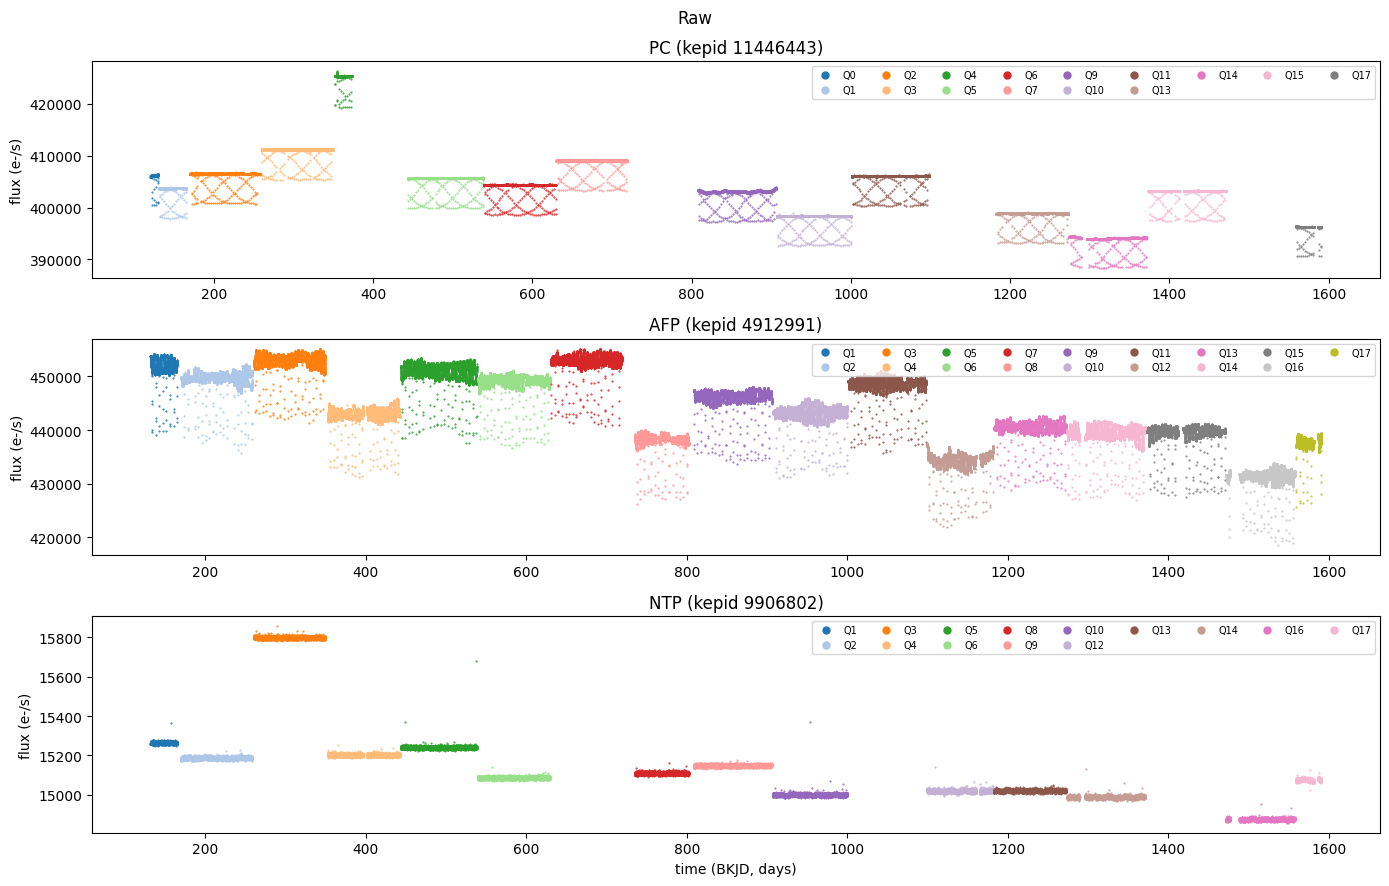

In [47]:
raw = {label: from_dir(kepid, MAST_TEST_DIR) for label, kepid in STARS.items()}
for label, quarters in raw.items():
    print(f"{label}: {len(quarters)} quarters, {sum(len(q.flux) for q in quarters)} points")
plot_quarters(raw, "Raw", "flux (e-/s)")

## 1. Drop Bad Points
Many of the following calculations require no NaN values in the data. Remove points when time or flux is NaN, or where the quality flag indicates a serious quality issue.

PC: kept 94.70%
AFP: kept 93.50%
NTP: kept 93.39%


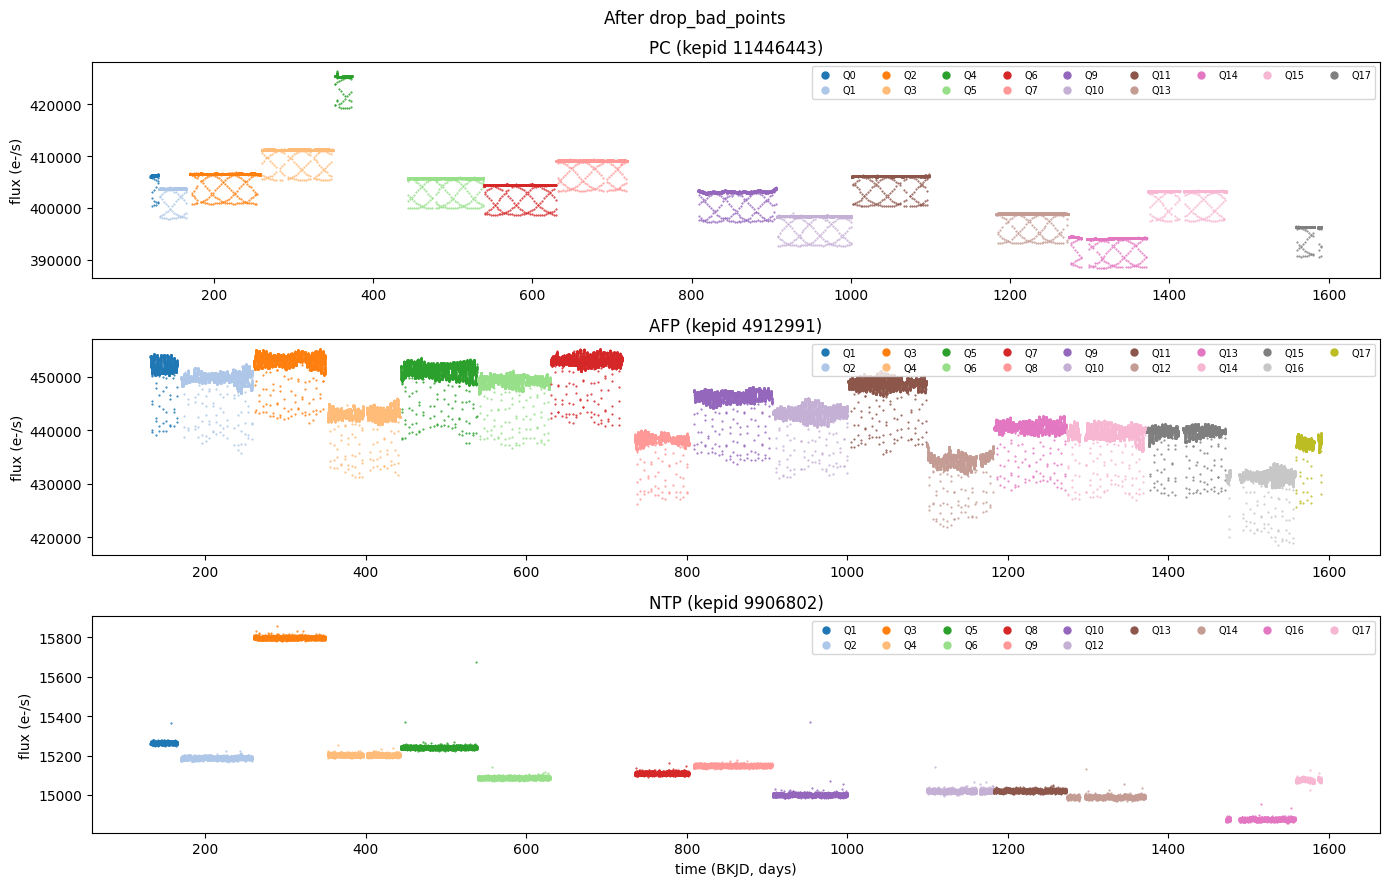

In [48]:
cleaned = {label: [p.drop_bad_points(q) for q in quarters] for label, quarters in raw.items()}
for label in STARS:
    print(f"{label}: kept {sum(len(q.flux) for q in cleaned[label])/sum(len(q.flux) for q in raw[label]) * 100:.2f}%")
plot_quarters(cleaned, "After drop_bad_points", "flux (e-/s)")

## 2. Scale each quarter
Each quarter's median can vary greatly due to the spacecraft's angle changing between quarters. Align the quarters by dividing each by its median. The baseline (median) should sit at 1 for all quarters.

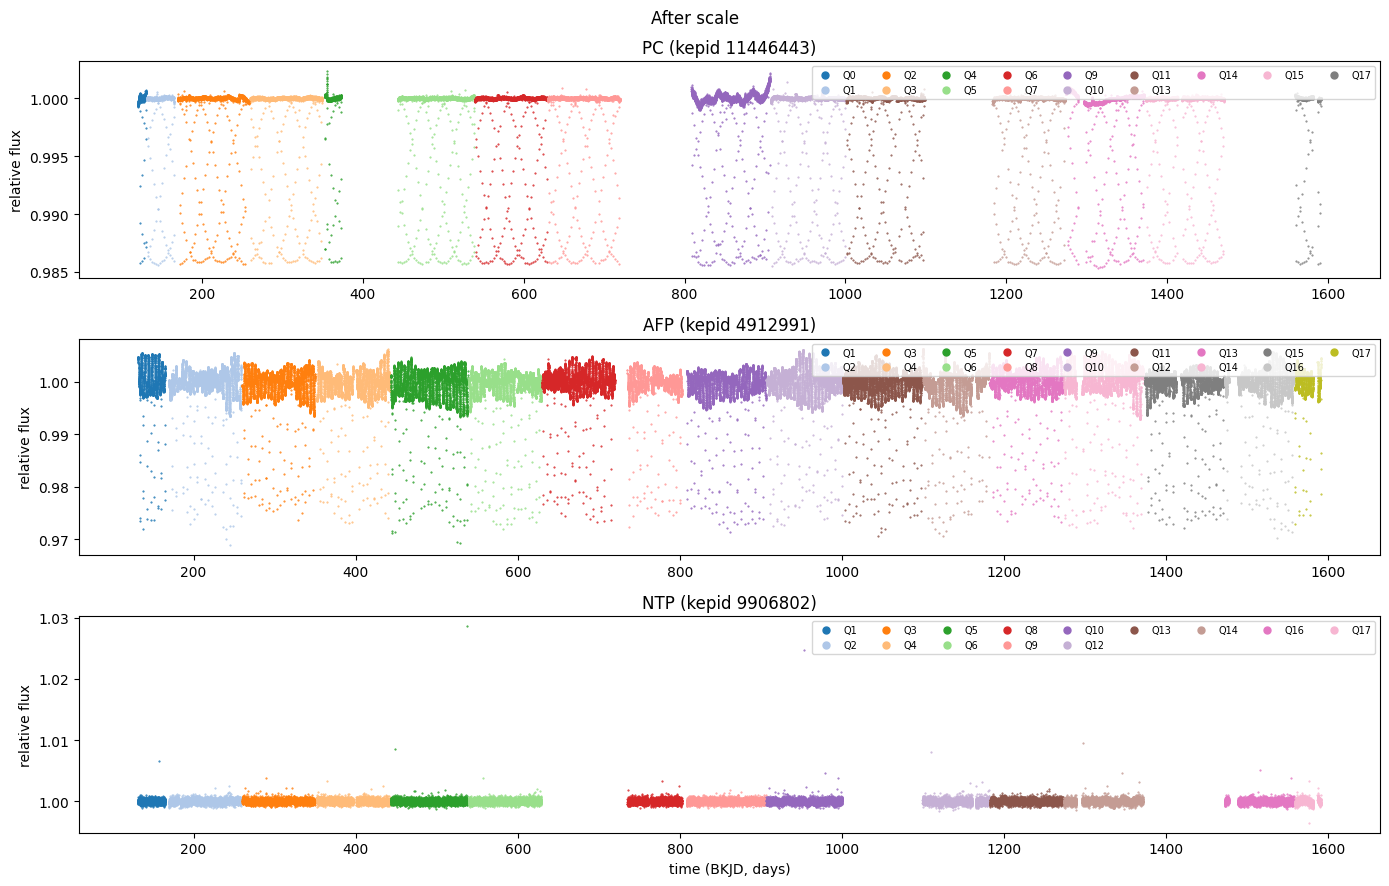

In [49]:
scaled = {label: [p.scale(q) for q in quarters if len(q.flux)] for label, quarters in cleaned.items()}
plot_quarters(scaled, "After scale", "relative flux")

## 3. Stitch quarters
Join each quarter into a single light curve per star (some quarters may not have any data - since the data will be phase-folded, that's okay).

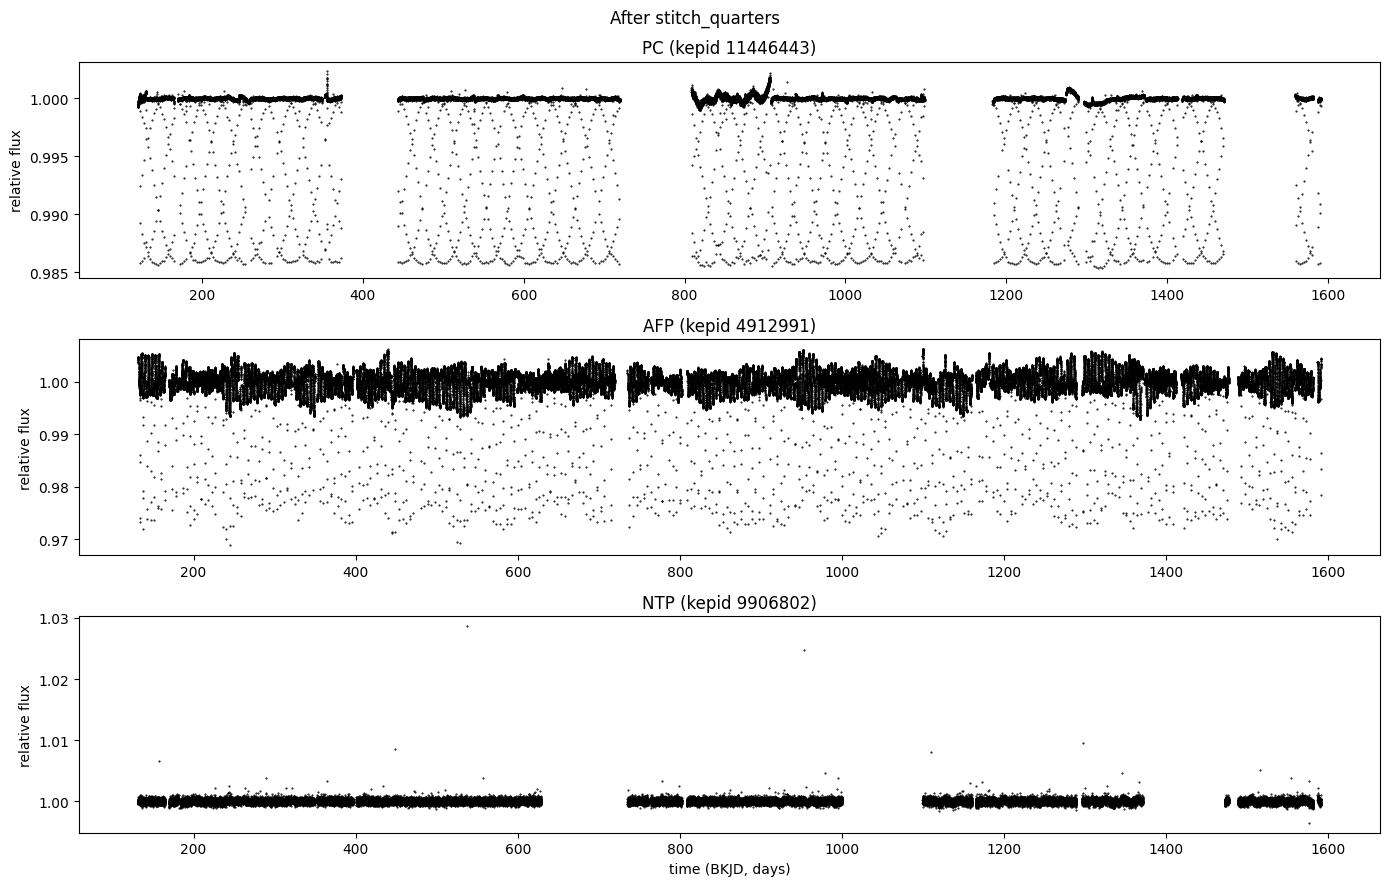

In [50]:
curves = {label: p.stitch_quarters(STARS[label], quarters) for label, quarters in scaled.items()}
plot_curves(curves, "After stitch_quarters", "relative flux")

## 4. Spline detrend
Reduce noise at the baseline by fitting a spline to it and pruning outliers (excluding in-transit points). 

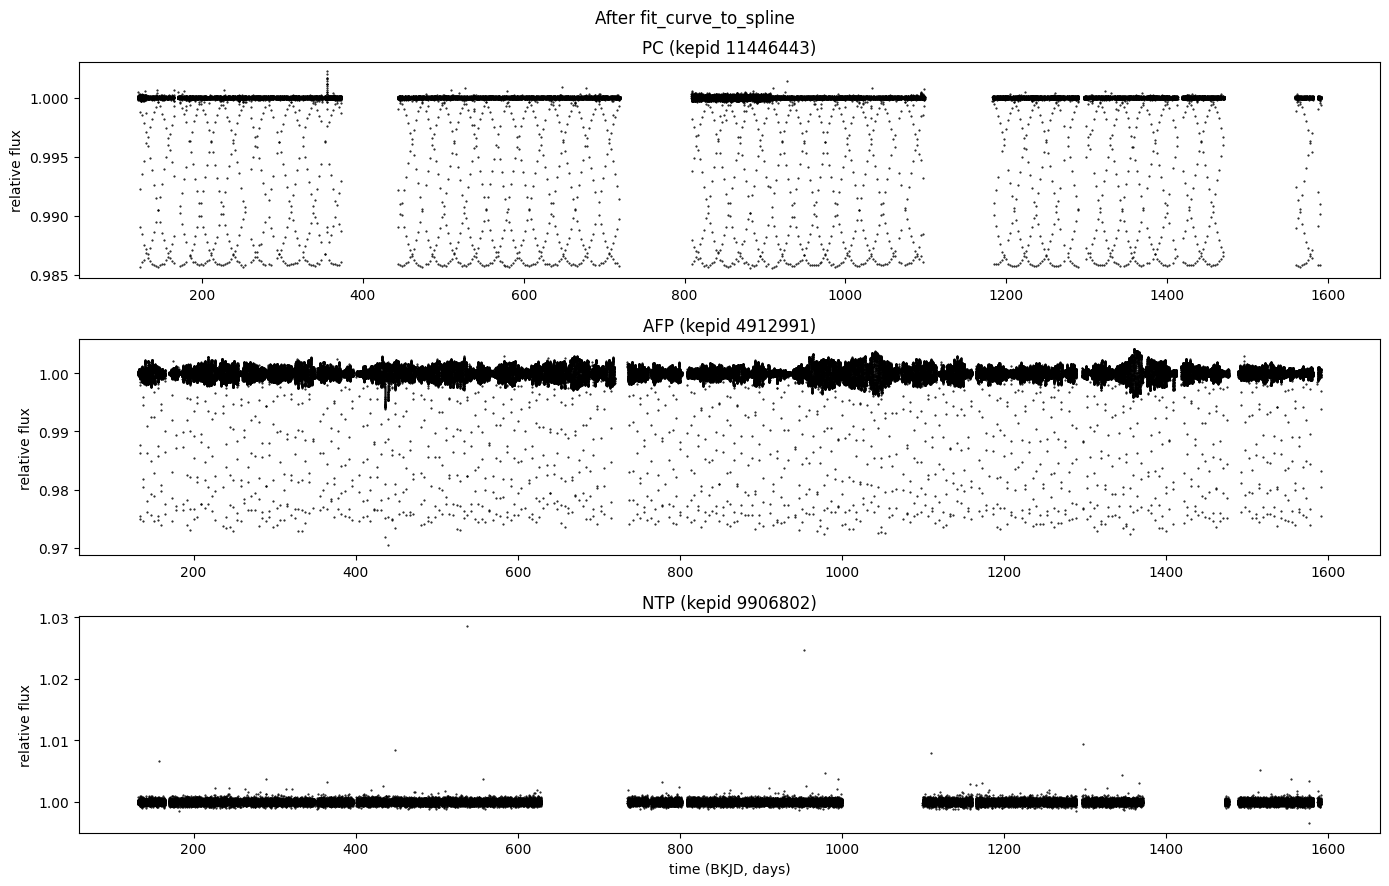

In [51]:
flat = {label: p.fit_curve_to_spline(curve, all_tces[all_tces.kepid == STARS[label]]) for label, curve in curves.items()}
plot_curves(flat, "After fit_curve_to_spline", "relative flux")

## 5. Phase fold
Fold the star's light curve using each of the TCE records. Rather than plotting by time, plot by phase (days from the nearest transit center) so that every transit event stacks at phase 0. This brings out the U-shaped dip that experts use for exoplanet classification.

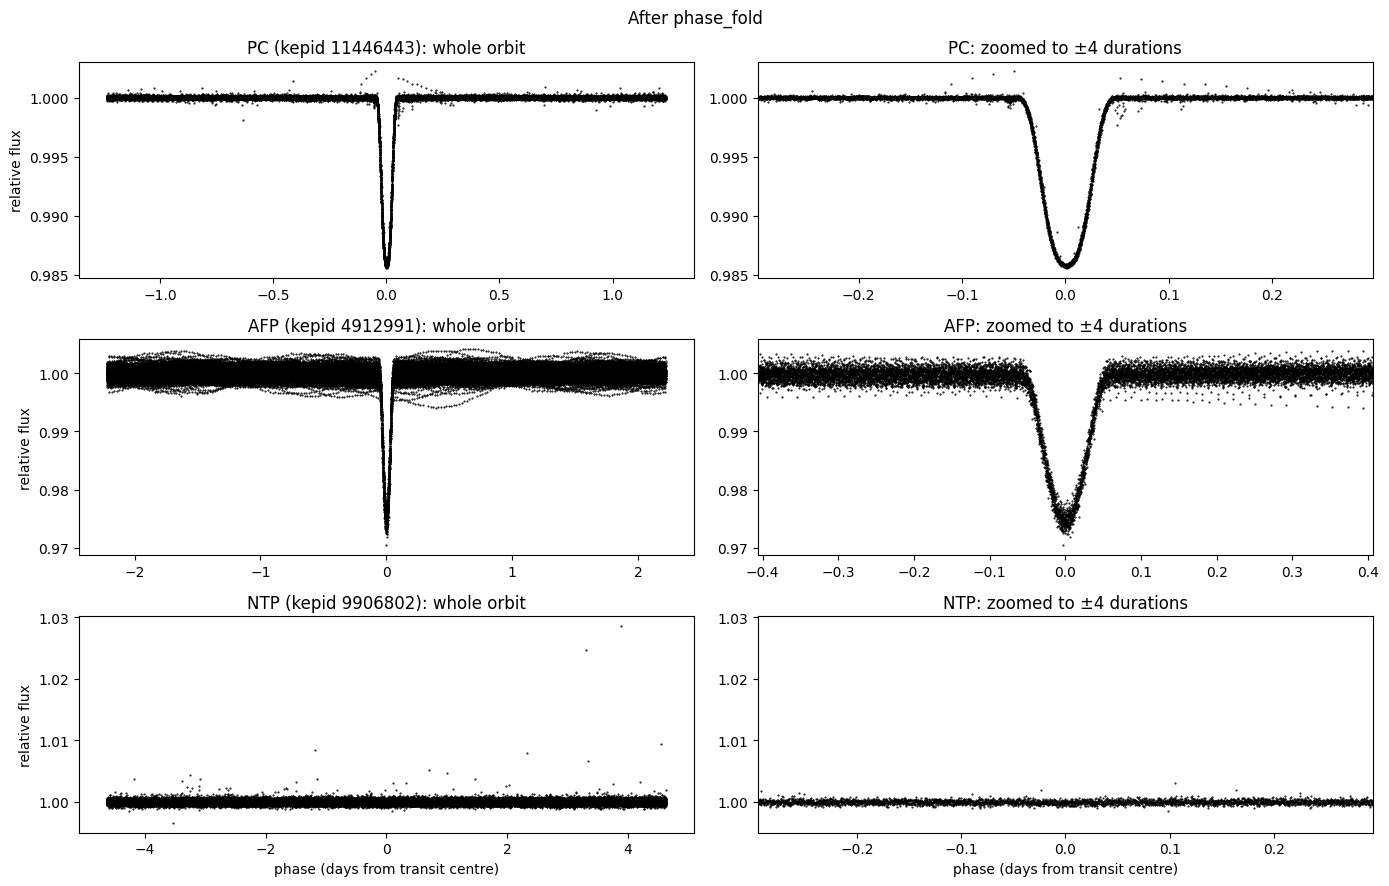

In [52]:
folded = {label: p.phase_fold(curve, TCE[label].tce_period, TCE[label].tce_time0bk) for label, curve in flat.items()}
plot_folded(folded, "After phase_fold")

## 6. Bin

CNNs require fixed size input lengths. Without binning, each TCE can have any number of data points in the flux array.

Divide the flux into equal-width bins and take the median of each bin as the new flux point. Create 2 distinct views:
- Global view: use 2001 bins over the whole orbit
- Local view: use 201 bins over only the interval ±4 transit durations.

If a bin has no points, that the value is NaN (filled later)

PC: empty bins global 0, local 0
AFP: empty bins global 0, local 0
NTP: empty bins global 0, local 0


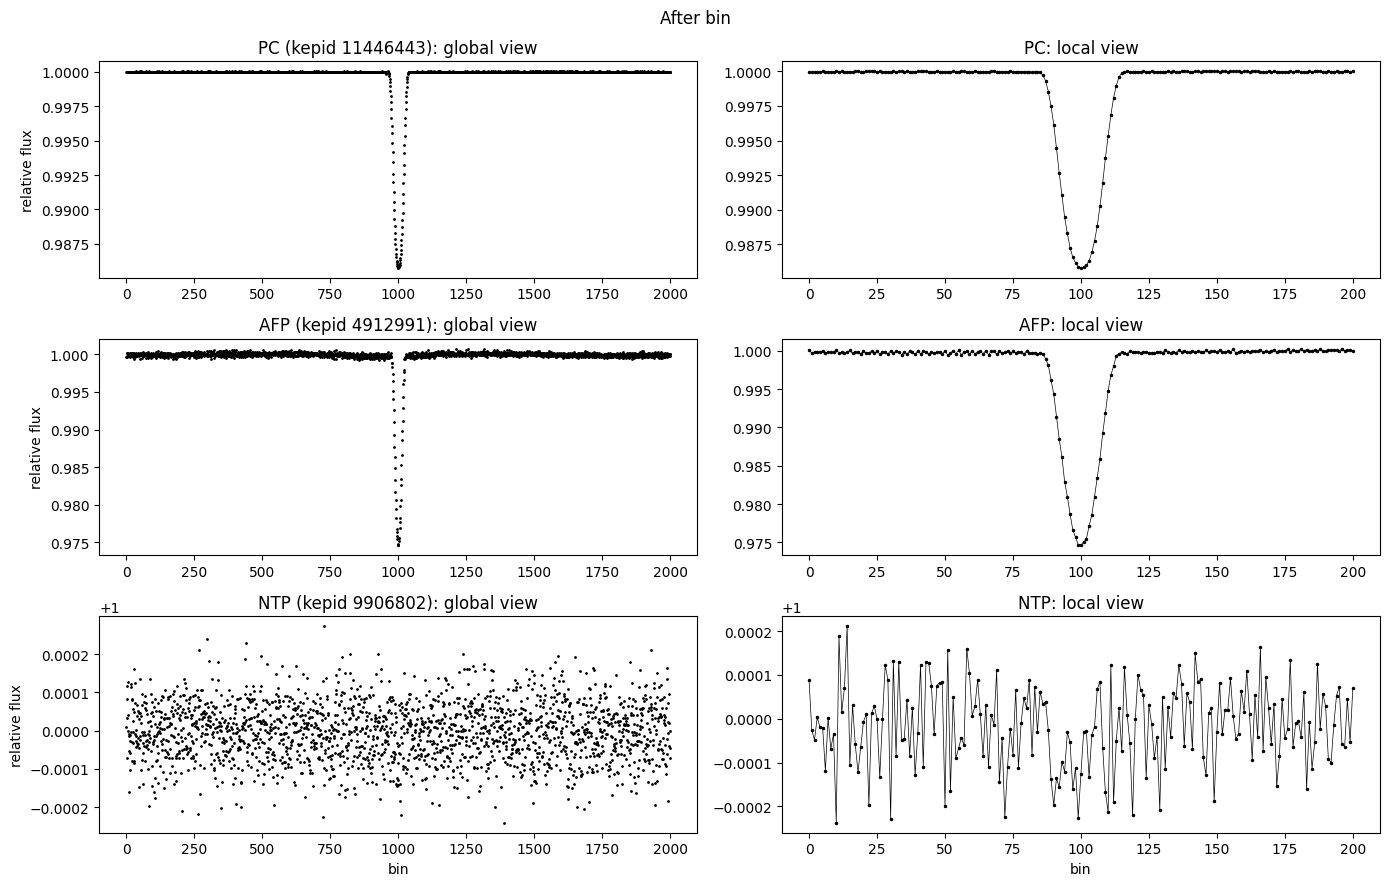

In [53]:
global_binned = {label: p.bin(f, 2001, TCE[label].tce_period / 2) for label, f in folded.items()}
local_binned = {
    label: p.bin(f, 201, min(4 * TCE[label].tce_duration / 24, TCE[label].tce_period / 2))
    for label, f in folded.items()
}
for label in STARS:
    print(f"{label}: empty bins global {np.isnan(global_binned[label]).sum()}, local {np.isnan(local_binned[label]).sum()}")
plot_views(global_binned, local_binned, "After bin", "relative flux")

## 7. Fill gaps
Empty bins are set to the view's median value (the flat baseline)

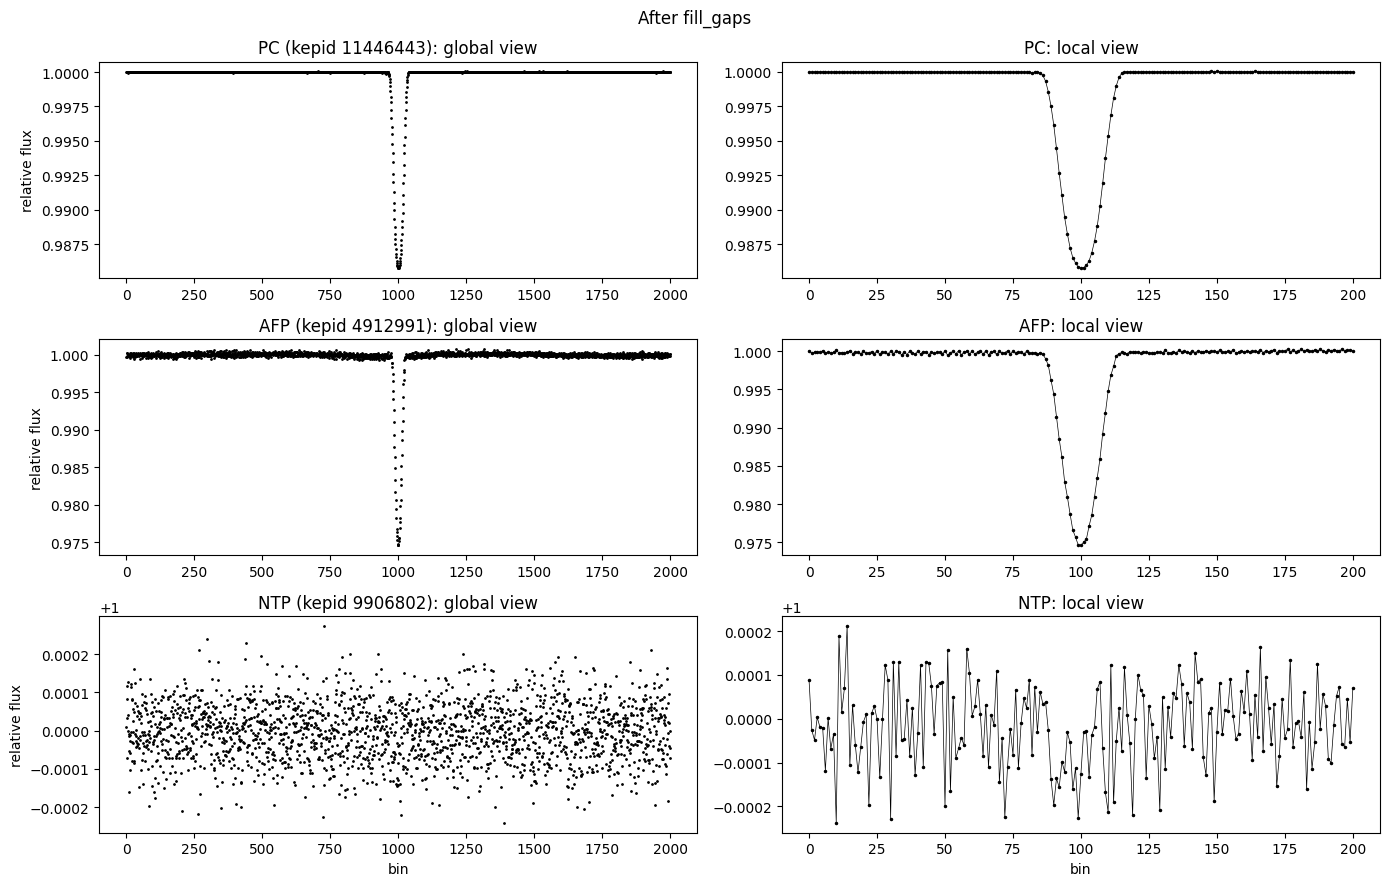

In [54]:
global_filled = {label: p.fill_gaps(v) for label, v in global_binned.items()}
local_filled = {label: p.fill_gaps(v) for label, v in local_binned.items()}
plot_views(global_filled, local_filled, "After fill_gaps", "relative flux")

## 8. Rescale
Rescale the curve so that the baseline (median) sits at 0, and the deepest point in the dip sits at -1. This is so that the CNN focuses on the *shape* of the curve, rather than the size.

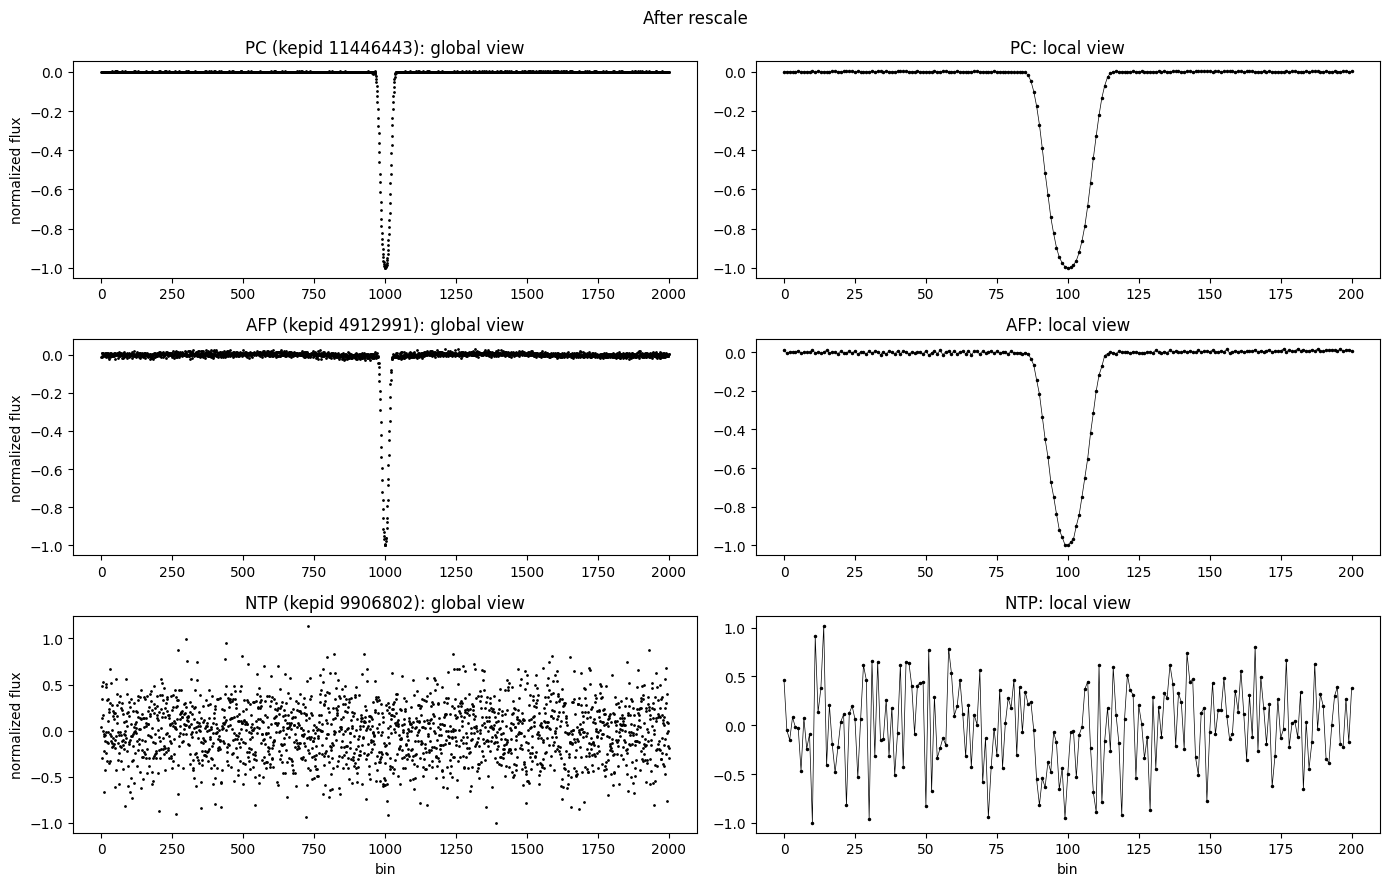

In [55]:
global_views = {label: p.rescale(v) for label, v in global_filled.items()}
local_views = {label: p.rescale(v) for label, v in local_filled.items()}
plot_views(global_views, local_views, "After rescale", "normalized flux")